# Week 3: KPI Development and Profitability Analysis
**CS Vision Data Analytics Internship – Set A | Financial & Operational Performance Analytics System**

**Dataset:** Global Superstore (clean version from Week 1): 51,290 order lines, 2011–2014.

**Objective:** Build measurable business KPIs, analyse profitability by product, region, market and discount level, calculate growth rates, detect anomalies, and turn the evidence into actionable business insights.

## 1. Setup and Load the Clean Dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from matplotlib.ticker import FuncFormatter

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 13, "axes.titleweight": "bold", "axes.labelsize": 10})

root = Path(r"C:\Users\tanis\OneDrive\Desktop\cs-vision-internship")
if not root.exists():                      # fallback: notebook is inside <project>/notebook
    root = Path.cwd().parent

df = pd.read_csv(root / "data" / "clean" / "clean_financial_data.csv", parse_dates=["Order_Date", "Ship_Date"])
VIS = root / "visualizations"; VIS.mkdir(exist_ok=True)

def save(name):
    plt.tight_layout()
    plt.savefig(VIS / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

money_k = FuncFormatter(lambda x, _: f"{x/1000:,.0f}K")
money_m = FuncFormatter(lambda x, _: f"{x/1e6:,.1f}M")
GOOD, BAD, BLUE, GOLD = "#2a9d8f", "#e63946", "#264653", "#e9c46a"
print("Loaded:", df.shape)

Loaded: (51290, 40)


## 2. Key Performance Indicators (KPIs)
Ten KPIs summarise financial and operational performance. **Total Expenses = Cost + Shipping Expense.**

In [2]:
revenue   = df.Sales.sum()
cost      = df.Cost.sum()
shipping  = df.Operating_Expense.sum()
expenses  = cost + shipping
gross     = df.Gross_Profit.sum()
net       = df.Net_Profit.sum()
orders    = df.Order_ID.nunique()

yearly = df.groupby("Year").Sales.sum()
cagr   = (yearly.iloc[-1] / yearly.iloc[0]) ** (1 / (len(yearly) - 1)) - 1

kpi = pd.DataFrame([
    ["Total Revenue",          revenue,              "Sum of Sales"],
    ["Total Expenses",         expenses,             "Cost + Shipping Cost"],
    ["Gross Profit",           gross,                "Sum of Profit (before shipping)"],
    ["Net Profit",             net,                  "Gross Profit - Shipping Cost"],
    ["Gross Margin %",         gross / revenue * 100, "Gross Profit / Revenue"],
    ["Net Profit Margin %",    net / revenue * 100,   "Net Profit / Revenue"],
    ["Revenue Growth Rate (CAGR 2011-2014) %", cagr * 100, "Compound annual growth of yearly revenue"],
    ["Average Transaction (Order) Value", revenue / orders, "Revenue / number of orders"],
    ["Cost-to-Revenue Ratio %", cost / revenue * 100, "Cost / Revenue"],
    ["Loss-making Order Lines %", (df.Net_Profit < 0).mean() * 100, "Share of lines with Net Profit < 0"],
], columns=["KPI", "Value", "Definition"])

kpi_show = kpi.copy()
kpi_show["Value"] = [f"{v:,.2f}" for v in kpi.Value]
print(kpi_show.to_string(index=False))
print("\nShipping cost as % of revenue:", round(shipping / revenue * 100, 2))
print("Total expense ratio %:", round(expenses / revenue * 100, 2))
kpi.to_csv(root / "data" / "clean" / "kpi_summary.csv", index=False)     # reused in the Week 4 dashboard

                                   KPI         Value                               Definition
                         Total Revenue 12,642,501.91                             Sum of Sales
                        Total Expenses 12,527,865.31                     Cost + Shipping Cost
                          Gross Profit  1,467,457.29          Sum of Profit (before shipping)
                            Net Profit    114,636.60             Gross Profit - Shipping Cost
                        Gross Margin %         11.61                   Gross Profit / Revenue
                   Net Profit Margin %          0.91                     Net Profit / Revenue
Revenue Growth Rate (CAGR 2011-2014) %         23.92 Compound annual growth of yearly revenue
     Average Transaction (Order) Value        504.99               Revenue / number of orders
               Cost-to-Revenue Ratio %         88.39                           Cost / Revenue
             Loss-making Order Lines %         41.24       S

## 3. Growth Rates

In [3]:
yearly_tbl = df.groupby("Year").agg(Sales=("Sales", "sum"), Gross_Profit=("Gross_Profit", "sum"),
                                    Net_Profit=("Net_Profit", "sum"), Orders=("Order_ID", "nunique"))
yearly_tbl["Revenue_Growth_%"] = yearly_tbl.Sales.pct_change() * 100
yearly_tbl["Net_Profit_Growth_%"] = yearly_tbl.Net_Profit.pct_change() * 100
yearly_tbl["Gross_Margin_%"] = yearly_tbl.Gross_Profit / yearly_tbl.Sales * 100
yearly_tbl["Net_Margin_%"]   = yearly_tbl.Net_Profit / yearly_tbl.Sales * 100
yearly_tbl["Avg_Order_Value"] = yearly_tbl.Sales / yearly_tbl.Orders
yearly_tbl.round(2)

,Sales,Gross_Profit,Net_Profit,Orders,Revenue_Growth_%,Net_Profit_Growth_%,Gross_Margin_%,Net_Margin_%,Avg_Order_Value
Year,,,,,,,,,
2011,2259450.90,248940.81,4669.73,4440,NaN,NaN,11.02,0.21,508.89
2012,2677438.69,307415.28,23923.39,5343,18.50,412.31,11.48,0.89,501.11
2013,3405746.45,406935.23,42385.28,6721,27.20,77.17,11.95,1.24,506.73
2014,4299865.87,504165.97,43658.20,8531,26.25,3.00,11.73,1.02,504.03


### Chart 16 – Monthly Revenue Growth Rate (Month-over-Month)

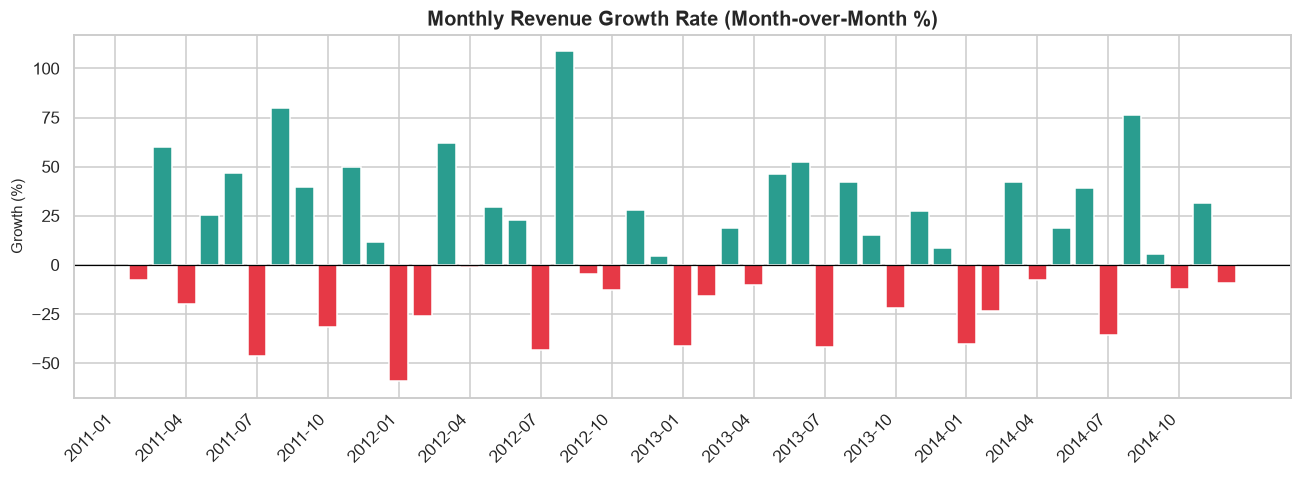

Average MoM growth %: 10.23 | Median MoM growth %: 8.41
Months with positive growth: 26 of 47
Largest rise : 2012-08 108.7 % | Largest fall: 2012-01 -59.3 %


In [4]:
monthly = df.groupby("Year_Month").Sales.sum()
mom = monthly.pct_change() * 100

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.bar(mom.index, mom.values, color=[GOOD if v >= 0 else BAD for v in mom.fillna(0)])
ax.axhline(0, color="black", lw=.8)
ax.set_xticks(range(0, len(mom), 3)); ax.set_xticklabels(mom.index[::3], rotation=45, ha="right")
ax.set(title="Monthly Revenue Growth Rate (Month-over-Month %)", xlabel="", ylabel="Growth (%)")
save("16_monthly_growth_rate")
print("Average MoM growth %:", round(mom.mean(), 2), "| Median MoM growth %:", round(mom.median(), 2))
print("Months with positive growth:", int((mom > 0).sum()), "of", int(mom.notna().sum()))
print("Largest rise :", mom.idxmax(), round(mom.max(), 1), "% | Largest fall:", mom.idxmin(), round(mom.min(), 1), "%")

## 4. Profitability Analysis

### Chart 17 – Gross vs Net Margin by Year

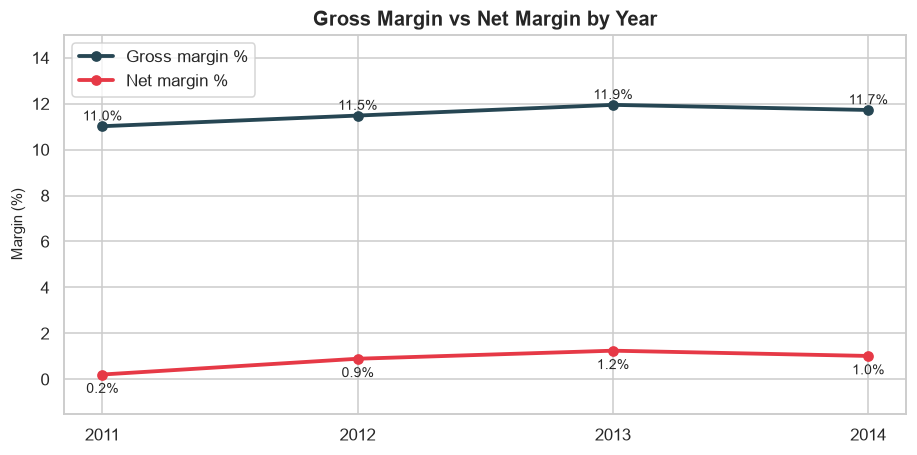

In [5]:
fig, ax = plt.subplots(figsize=(8.5, 4.3))
ax.plot(yearly_tbl.index, yearly_tbl["Gross_Margin_%"], marker="o", lw=2.5, color=BLUE, label="Gross margin %")
ax.plot(yearly_tbl.index, yearly_tbl["Net_Margin_%"], marker="o", lw=2.5, color=BAD, label="Net margin %")
for x, g, n in zip(yearly_tbl.index, yearly_tbl["Gross_Margin_%"], yearly_tbl["Net_Margin_%"]):
    ax.text(x, g + .25, f"{g:.1f}%", ha="center", fontsize=9); ax.text(x, n - .8, f"{n:.1f}%", ha="center", fontsize=9)
ax.set_xticks(yearly_tbl.index); ax.set_ylim(-1.5, 15); ax.legend()
ax.set(title="Gross Margin vs Net Margin by Year", xlabel="", ylabel="Margin (%)")
save("17_margin_by_year")

### Chart 18 – From Revenue to Net Profit (Profit Waterfall)

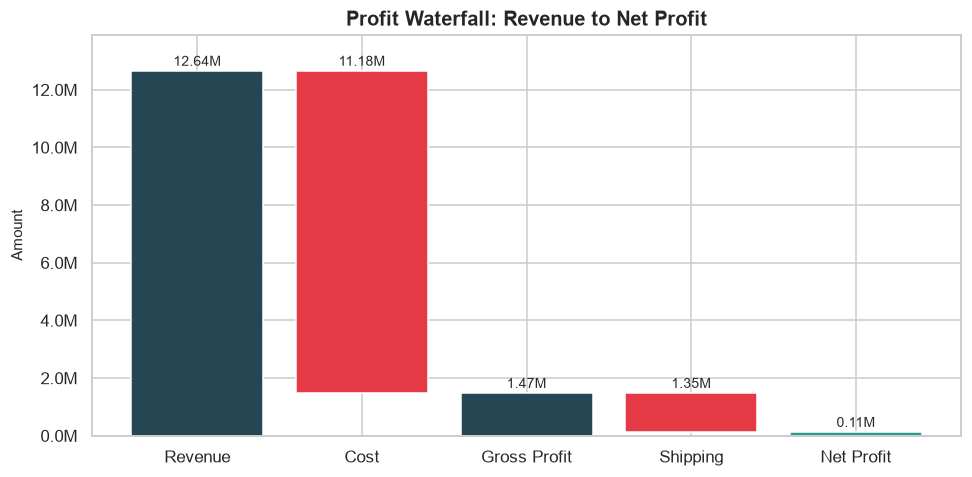

In [6]:
steps = [("Revenue", revenue), ("Cost", -cost), ("Gross Profit", gross), ("Shipping", -shipping), ("Net Profit", net)]
fig, ax = plt.subplots(figsize=(9, 4.5))
running = 0
for i, (lab, v) in enumerate(steps):
    if lab in ("Revenue", "Gross Profit", "Net Profit"):
        ax.bar(i, v, color=BLUE if lab != "Net Profit" else GOOD); running = v; label_y = v
    else:
        before = running
        ax.bar(i, v, bottom=before, color=BAD); running = before + v; label_y = before
    ax.text(i, label_y + revenue * .015, f"{abs(v)/1e6:,.2f}M", ha="center", fontsize=9)
ax.set_ylim(0, revenue * 1.1)
ax.set_xticks(range(len(steps))); ax.set_xticklabels([s[0] for s in steps]); ax.yaxis.set_major_formatter(money_m)
ax.set(title="Profit Waterfall: Revenue to Net Profit", ylabel="Amount")
save("18_profit_waterfall")

### Product-Level Profitability

In [7]:
prod = df.groupby("Product_Name").agg(Sales=("Sales", "sum"), Net_Profit=("Net_Profit", "sum"), Units=("Quantity", "sum"))
prod["Net_Margin_%"] = prod.Net_Profit / prod.Sales * 100
prod["Sales_Share_%"] = prod.Sales / prod.Sales.sum() * 100
print("Products:", len(prod), "| Profitable:", int((prod.Net_Profit > 0).sum()), "| Loss-making:", int((prod.Net_Profit < 0).sum()))
print("Top 10 products' share of total sales: %.1f%%" % prod.Sales.nlargest(10).sum().__truediv__(revenue).__mul__(100))
print("\nTOP 10 PRODUCTS BY NET PROFIT"); print(prod.sort_values("Net_Profit", ascending=False).head(10).round(1).to_string())
print("\nBOTTOM 10 PRODUCTS BY NET PROFIT"); print(prod.sort_values("Net_Profit").head(10).round(1).to_string())

Products: 3788 | Profitable: 2351 | Loss-making: 1437
Top 10 products' share of total sales: 4.9%

TOP 10 PRODUCTS BY NET PROFIT
                                         Sales  Net_Profit  Units  Net_Margin_%  Sales_Share_%
Product_Name                                                                                  
Canon imageCLASS 2200 Advanced Copier  61599.8     23923.6     20          38.8            0.5
Cisco Smart Phone, Full Size           76441.5     10173.4    139          13.3            0.6
Hoover Stove, Red                      31663.8      8319.2     62          26.3            0.3
Motorola Smart Phone, Full Size        73156.3      8209.8    134          11.2            0.6
Sauder Classic Bookcase, Traditional   39108.3      6568.4    113          16.8            0.3
Belkin Router, USB                     23470.4      6439.5    110          27.4            0.2
Hewlett Wireless Fax, High-Speed       23810.6      6153.1     75          25.8            0.2
Canon Wireless F

### Chart 19 – Sub-Category Profitability Matrix (Contribution vs Margin)

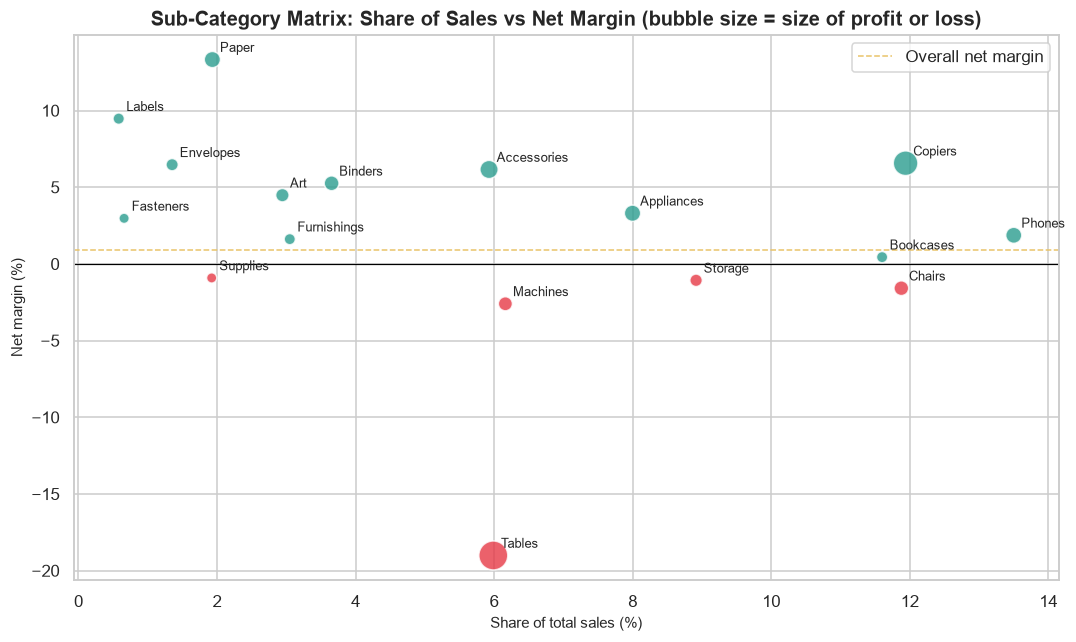

,Sales,Net_Profit,Sales_Share_%,Net_Margin_%
Sub_Category,,,,
Copiers,1509436.27,99071.06,11.94,6.56
Accessories,749237.02,46112.73,5.93,6.15
Appliances,1011064.30,33379.81,8.00,3.30
Paper,244291.72,32546.39,1.93,13.32
Phones,1706824.14,31814.24,13.50,1.86
Binders,461911.51,24267.86,3.65,5.25
Art,372091.97,16666.44,2.94,4.48
Envelopes,170904.30,11053.34,1.35,6.47
Labels,73404.03,6950.63,0.58,9.47


In [8]:
sub = df.groupby("Sub_Category").agg(Sales=("Sales", "sum"), Net_Profit=("Net_Profit", "sum"))
sub["Sales_Share_%"] = sub.Sales / revenue * 100
sub["Net_Margin_%"] = sub.Net_Profit / sub.Sales * 100

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(sub["Sales_Share_%"], sub["Net_Margin_%"], s=abs(sub.Net_Profit) / 450 + 40,
           c=[GOOD if v >= 0 else BAD for v in sub.Net_Profit], alpha=.8, edgecolor="white")
for name, r in sub.iterrows(): ax.annotate(name, (r["Sales_Share_%"], r["Net_Margin_%"]), xytext=(5, 5), textcoords="offset points", fontsize=8.5)
ax.axhline(0, color="black", lw=.8); ax.axhline(net / revenue * 100, color=GOLD, ls="--", lw=1, label="Overall net margin")
ax.legend(); ax.set(title="Sub-Category Matrix: Share of Sales vs Net Margin (bubble size = size of profit or loss)",
                    xlabel="Share of total sales (%)", ylabel="Net margin (%)")
save("19_subcategory_matrix")
sub.sort_values("Net_Profit", ascending=False).round(2)

### Chart 20 – Market Contribution and Profitability

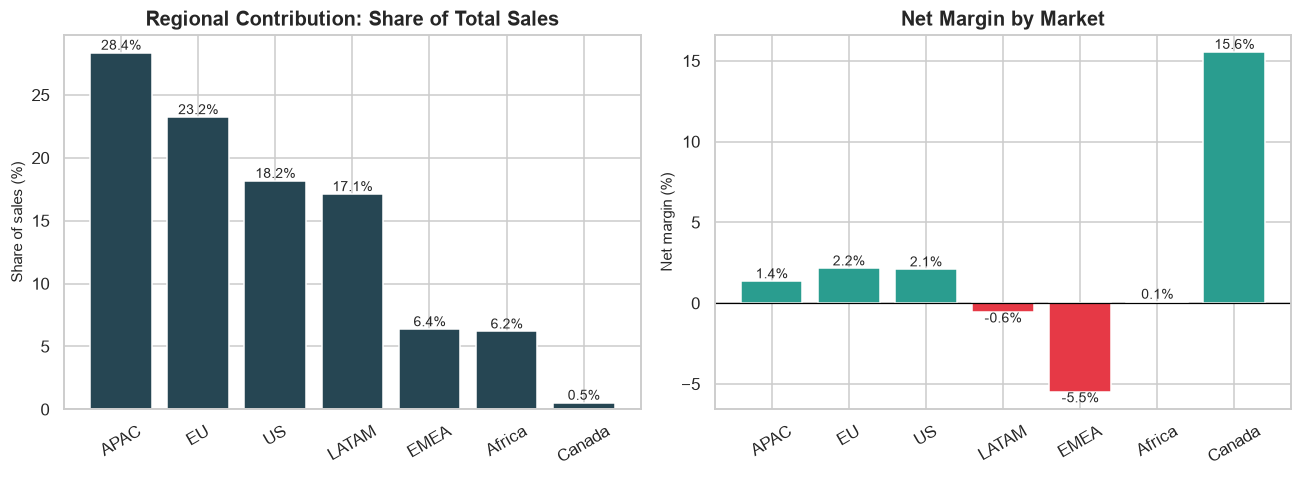

,Sales,Net_Profit,Sales_Share_%,Net_Margin_%
Market,,,,
APAC,3585744.13,48834.94,28.36,1.36
EU,2938089.06,63407.39,23.24,2.16
US,2297200.86,48223.23,18.17,2.10
LATAM,2164605.17,-12495.12,17.12,-0.58
EMEA,806161.31,-44477.76,6.38,-5.52
Africa,783773.21,732.16,6.20,0.09
Canada,66928.17,10411.76,0.53,15.56


In [9]:
mk = df.groupby("Market").agg(Sales=("Sales", "sum"), Net_Profit=("Net_Profit", "sum")).sort_values("Sales", ascending=False)
mk["Sales_Share_%"] = mk.Sales / revenue * 100
mk["Net_Margin_%"] = mk.Net_Profit / mk.Sales * 100

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].bar(mk.index, mk["Sales_Share_%"], color=BLUE)
for i, v in enumerate(mk["Sales_Share_%"]): ax[0].text(i, v, f"{v:.1f}%", ha="center", va="bottom", fontsize=9)
ax[0].set(title="Regional Contribution: Share of Total Sales", xlabel="", ylabel="Share of sales (%)")
ax[1].bar(mk.index, mk["Net_Margin_%"], color=[GOOD if v >= 0 else BAD for v in mk["Net_Margin_%"]])
for i, v in enumerate(mk["Net_Margin_%"]): ax[1].text(i, v, f"{v:.1f}%", ha="center", va="bottom" if v >= 0 else "top", fontsize=9)
ax[1].axhline(0, color="black", lw=.8); ax[1].set(title="Net Margin by Market", xlabel="", ylabel="Net margin (%)")
for a in ax: a.tick_params(axis="x", rotation=30)
save("20_market_contribution")
mk.round(2)

### Region Profitability Ranking

In [10]:
reg = df.groupby("Region").agg(Sales=("Sales", "sum"), Net_Profit=("Net_Profit", "sum"))
reg["Sales_Share_%"] = reg.Sales / revenue * 100
reg["Net_Margin_%"] = reg.Net_Profit / reg.Sales * 100
reg.sort_values("Net_Profit", ascending=False).round(2)

,Sales,Net_Profit,Sales_Share_%,Net_Margin_%
Region,,,,
North Asia,848309.78,70547.81,6.71,8.32
North,1248165.60,63123.86,9.87,5.06
Central Asia,752826.57,54650.04,5.95,7.26
West,725457.82,31906.19,5.74,4.40
East,678781.24,18779.16,5.37,2.77
Central,2822302.52,14463.42,22.32,0.51
Canada,66928.17,10411.76,0.53,15.56
Africa,783773.21,732.16,6.20,0.09
Oceania,1100184.61,-539.40,8.70,-0.05


### Chart 21 – Discount Level and Category: Average Net Profit per Order Line

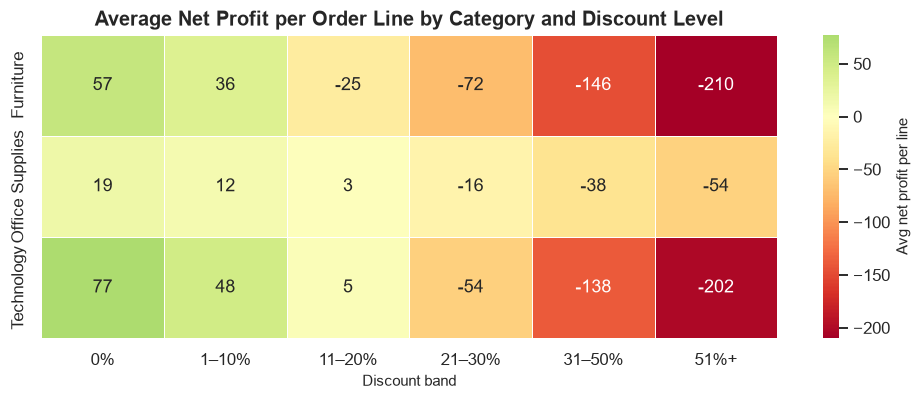

Lines with discount > 20%: 11328 (22.1% of lines)
Their total net profit: -1018666
Net profit excluding those lines: 1133303


In [11]:
bands = pd.cut(df.Discount, [-0.001, 0, 0.1, 0.2, 0.3, 0.5, 1.0], labels=["0%", "1–10%", "11–20%", "21–30%", "31–50%", "51%+"])
heat = df.assign(Band=bands).pivot_table(index="Category", columns="Band", values="Net_Profit", aggfunc="mean", observed=True)
fig, ax = plt.subplots(figsize=(9, 3.8))
sns.heatmap(heat, annot=True, fmt=".0f", cmap="RdYlGn", center=0, linewidths=.5, ax=ax, cbar_kws={"label": "Avg net profit per line"})
ax.set(title="Average Net Profit per Order Line by Category and Discount Level", xlabel="Discount band", ylabel="")
save("21_discount_category_heatmap")
disc_loss = df[df.Discount > 0.2]
print("Lines with discount > 20%:", len(disc_loss), f"({len(disc_loss)/len(df)*100:.1f}% of lines)")
print("Their total net profit:", round(disc_loss.Net_Profit.sum()))
print("Net profit excluding those lines:", round(df[df.Discount <= 0.2].Net_Profit.sum()))

## 5. Anomaly Detection
Two methods are used: the **z-score** (values more than 3 standard deviations from the mean) and the **IQR rule** flags created in Week 1 (within each sub-category).

In [12]:
z_net = (df.Net_Profit - df.Net_Profit.mean()) / df.Net_Profit.std()
z_sales = (df.Sales - df.Sales.mean()) / df.Sales.std()
df["Anomaly_Z"] = (z_net.abs() > 3) | (z_sales.abs() > 3)

print("Net profit |z| > 3 :", int((z_net.abs() > 3).sum()))
print("Sales |z| > 3      :", int((z_sales.abs() > 3).sum()))
print("Either (Z anomalies):", int(df.Anomaly_Z.sum()), f"({df.Anomaly_Z.mean()*100:.2f}% of lines)")
print("IQR flags - Sales:", int(df.Sales_Outlier.sum()), "| Profit:", int(df.Profit_Outlier.sum()))
print("\nNet profit of z-score anomalies: ", round(df.loc[df.Anomaly_Z, "Net_Profit"].sum()))
print("Net profit of all other lines:   ", round(df.loc[~df.Anomaly_Z, "Net_Profit"].sum()))

print("\nTOP 10 LARGEST LOSSES")
cols = ["Order_ID", "Product_Name", "Region", "Sales", "Discount", "Shipping_Cost", "Net_Profit"]
df.nsmallest(10, "Net_Profit")[cols].round(2)

Net profit |z| > 3 : 820
Sales |z| > 3      : 1020
Either (Z anomalies): 1435 (2.80% of lines)
IQR flags - Sales: 1605 | Profit: 3106

Net profit of z-score anomalies:  -19778
Net profit of all other lines:    134414

TOP 10 LARGEST LOSSES


,Order_ID,Product_Name,Region,Sales,Discount,Shipping_Cost,Net_Profit
31906,CA-2013-108196,Cubify CubeX 3D Printer Double Head Print,East,4499.98,0.7,451.63,-7051.61
47218,US-2014-168116,Cubify CubeX 3D Printer Triple Head Print,South,7999.98,0.5,674.82,-4514.81
29240,TU-2013-9400,"Motorola Smart Phone, Cordless",EMEA,3085.34,0.6,51.89,-4140.27
3787,CA-2011-169019,GBC DocuBind P400 Electric Binding System,Central,2177.58,0.8,172.07,-3873.96
37137,CA-2014-134845,Lexmark MX611dhe Monochrome Laser Printer,West,2549.98,0.7,120.31,-3520.29
24284,IT-2013-3695467,"Hoover Stove, White",South,3399.66,0.5,286.87,-3346.69
28545,ID-2013-12295,"Apple Smart Phone, Full Size",Central Asia,3499.16,0.5,333.10,-3342.54
34550,LH-2014-5390,"Barricks Conference Table, Rectangular",EMEA,2171.16,0.7,390.09,-3140.37
49665,US-2014-122714,Ibico EPK-21 Electric Binding System,Central,1889.99,0.8,129.51,-3058.99
19264,CA-2012-147830,Cubify CubeX 3D Printer Double Head Print,East,1799.99,0.7,219.62,-2859.61


In [13]:
# Extreme discount lines and unusually expensive shipping
extreme_disc = df[df.Discount >= 0.7]
print("Lines with discount >= 70%:", len(extreme_disc), "| total net profit:", round(extreme_disc.Net_Profit.sum()))
print("Lines where shipping cost exceeds 50% of sales:", int((df.Shipping_Cost > 0.5 * df.Sales).sum()))

# Unusual months (z-score of monthly sales and monthly net profit)
m = df.groupby("Year_Month")[["Sales", "Net_Profit"]].sum()
m["z_sales"] = (m.Sales - m.Sales.mean()) / m.Sales.std()
m["z_net"] = (m.Net_Profit - m.Net_Profit.mean()) / m.Net_Profit.std()
m[(m.z_sales.abs() > 2) | (m.z_net.abs() > 2)].round(2)

Lines with discount >= 70%: 2104 | total net profit: -245860
Lines where shipping cost exceeds 50% of sales: 15


,Sales,Net_Profit,z_sales,z_net
Year_Month,,,,
2014-09,481157.24,14493.73,1.91,2.43
2014-10,422766.63,13587.13,1.40,2.25
2014-11,555279.03,2937.91,2.56,0.11
2014-12,503143.69,-7937.58,2.11,-2.07


### Chart 22 – Anomalies: Sales vs Net Profit

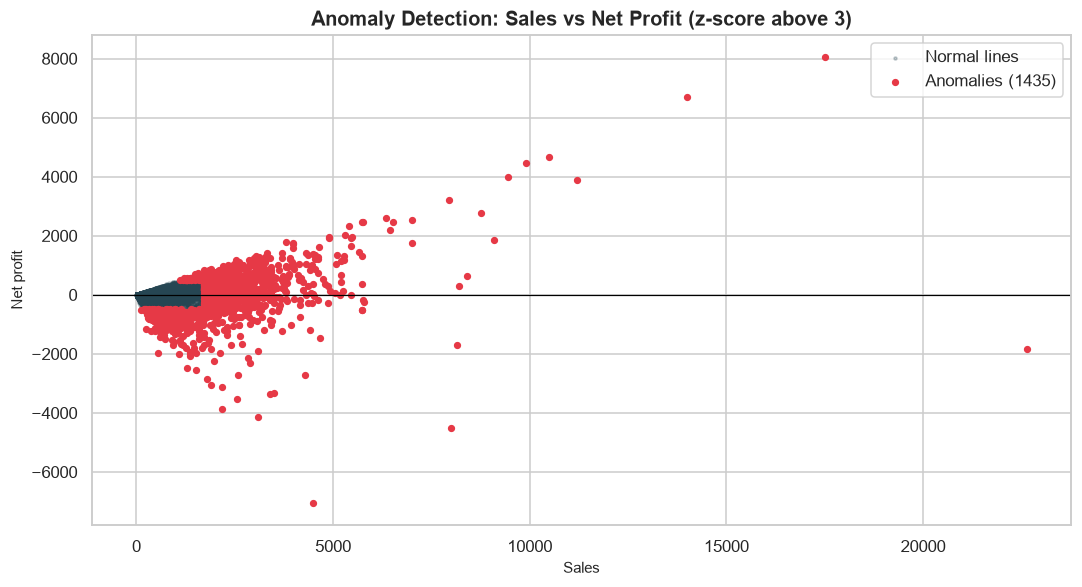

In [14]:
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.scatter(df.Sales[~df.Anomaly_Z], df.Net_Profit[~df.Anomaly_Z], s=4, alpha=.25, color=BLUE, label="Normal lines")
ax.scatter(df.Sales[df.Anomaly_Z], df.Net_Profit[df.Anomaly_Z], s=14, color=BAD, label=f"Anomalies ({int(df.Anomaly_Z.sum())})")
ax.axhline(0, color="black", lw=.8); ax.legend()
ax.set(title="Anomaly Detection: Sales vs Net Profit (z-score above 3)", xlabel="Sales", ylabel="Net profit")
save("22_anomaly_scatter")

### Chart 23 – Top and Bottom 10 Products by Net Profit

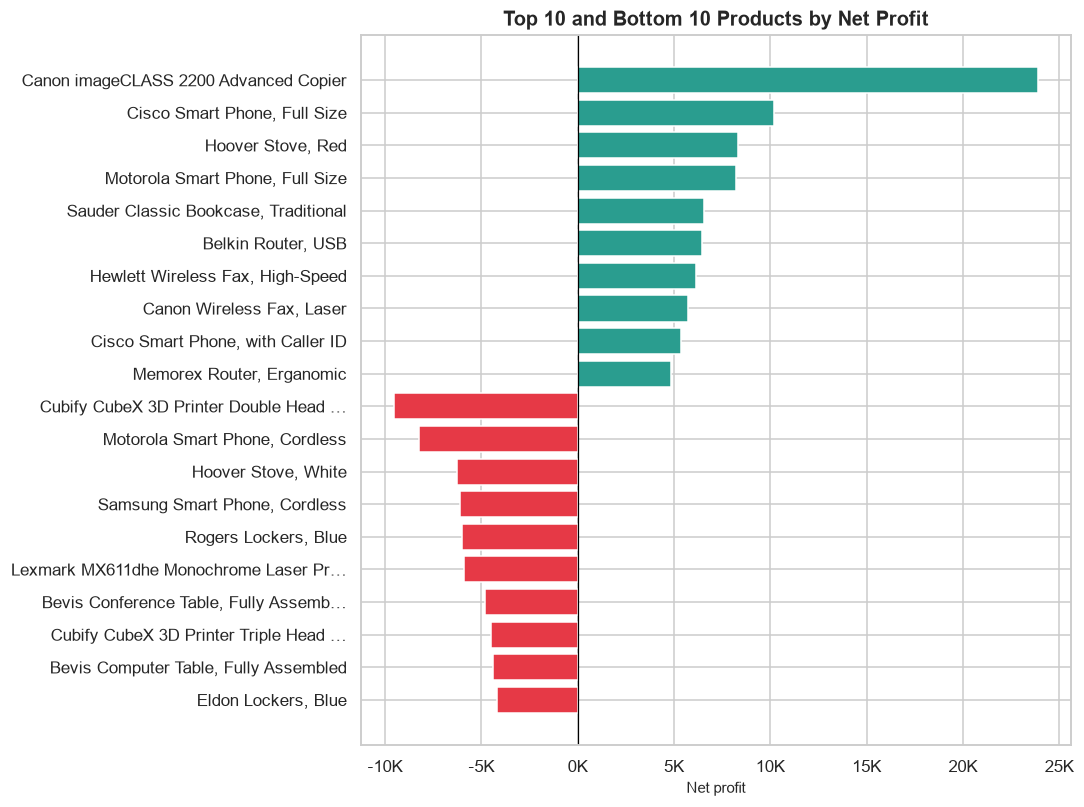

In [15]:
top = prod.sort_values("Net_Profit", ascending=False).head(10)
bot = prod.sort_values("Net_Profit").head(10)
both = pd.concat([bot.sort_values("Net_Profit", ascending=False), top.sort_values("Net_Profit")])
labels = [n if len(n) <= 38 else n[:36] + "…" for n in both.index]
fig, ax = plt.subplots(figsize=(10, 7.5))
ax.barh(labels, both.Net_Profit, color=[GOOD if v >= 0 else BAD for v in both.Net_Profit])
ax.axvline(0, color="black", lw=.8); ax.xaxis.set_major_formatter(money_k)
ax.set(title="Top 10 and Bottom 10 Products by Net Profit", xlabel="Net profit", ylabel="")
save("23_top_bottom_products")

## 6. Chart Inventory

In [16]:
files = sorted(p.name for p in VIS.glob("*.png"))
print(len(files), "charts in", VIS)
print([f for f in files if int(f[:2]) >= 16])

23 charts in C:\Users\tanis\OneDrive\Desktop\cs-vision-internship\visualizations
['16_monthly_growth_rate.png', '17_margin_by_year.png', '18_profit_waterfall.png', '19_subcategory_matrix.png', '20_market_contribution.png', '21_discount_category_heatmap.png', '22_anomaly_scatter.png', '23_top_bottom_products.png']


## 7. Business Insights and Recommendations

| # | Insight (with evidence) | Recommendation |
|---|---|---|
| 1 | **Strong, order-driven growth.** Revenue grew from 2.26M to 4.30M (CAGR 23.9%), but average order value stayed flat at about 505. | Raise basket size with bundles and cross-selling. |
| 2 | **Margins are very thin.** Gross margin is 11.6% and net margin 0.91%; expenses absorb 99.1% of revenue. Net margin fell from 1.24% (2013) to 1.02% (2014) while revenue grew 26%. | Set a net-margin target and track it monthly. |
| 3 | **Discounts above 20% are the biggest profit leak.** They cover 22.1% of lines and 15.3% of sales, with a margin of −52.8% and total loss of 1.02M. All other lines earn a 10.6% margin (+1.13M). | Cap discounts at 20% and require approval above it. |
| 4 | **Four sub-categories lose money.** Tables (−143.9K, −19% margin), Chairs (−23.8K), Machines (−20.3K) and Storage (−12.1K) lose about 200K together. | Reprice and limit discounts on these items. |
| 5 | **Profit is concentrated in Copiers.** Copiers earn 99.1K (6.6% margin), which is 86% of total net profit; the Canon imageCLASS 2200 alone earns 23.9K (38.8% margin). | Protect stock and promote high-margin technology. |
| 6 | **A long tail of loss-making products.** 1,437 of 3,788 products (37.9%) lose money; the worst, the Cubify CubeX 3D Printer, loses 9.6K (−86% margin). The top 10 products are only 4.9% of sales. | Review and prune products with persistent losses. |
| 7 | **Markets differ sharply.** EU (2.2%) and US (2.1%) are the best large markets; Canada has 15.6% on tiny volume; LATAM (−0.6%, −12.5K) and EMEA (−5.5%, −44.5K) lose money; APAC is the largest (28.4% of sales) at only 1.4%. | Fix pricing and shipping in LATAM and EMEA; improve APAC margin. |
| 8 | **Peak season does not convert to profit.** Only 26 of 47 months grew; November 2014 had 555K sales but just 2.9K profit, and December 2014 lost 7.9K. | Avoid deep discounts in Q4 and plan stock earlier. |
| 9 | **Anomalies are mostly extreme discounts.** 1,435 lines (2.8%) are z-score anomalies. Lines with discounts of 70% or more number 2,104 and lose 245.9K; the 10 largest losses all had discounts of 50–80%. | Add alerts and approval for discounts of 50% or more. |
| 10 | **Shipping is a major cost.** It is 10.7% of sales, and 41.2% of lines lose money after shipping; Same Day and First Class cost about 17% of sales against 8% for Standard Class (Week 2). | Add shipping surcharges or free-shipping thresholds, and steer customers to Standard Class. |